# Longer training for the highest-scoring model

The user reports that `submission_final_model_improvements.csv` scored **0.98629** on Kaggle, above `candidate_01` (0.98379), `candidate_04` (0.98363) and `candidate_03` (0.98326). These are user-reported public scores, not API-verified results. This experiment extends the original nine-specialist corrected-v3 recipe, keeping its features, learning rates, regularization, seed, three linear specialists and ensemble weights fixed.

All source work is in this notebook under `submissions/team-35/plum/`; generated artifacts live in `artifacts/longer_training_iterations/`. The supplied data and previous notebooks/results are read-only inputs. No test fitting, external labels, model downloads or Kaggle uploads.

Run from this notebook's directory. Prerequisites are the original `final_model_improvements.ipynb`, its audited artifacts/configuration, and `further_model_tuning.ipynb` for the reusable definition loader. No additional package installation is needed.


## Plan and success criteria

1. Load only the existing definition cells and verify source/configuration/data hashes, the fixed 8,000/2,000 partition and grouped folds. Verify on small fitted examples that each library's tree-prefix predictions equal independent shorter fits.
2. Fit each of the six boosting specialists once to the maximum training budget in each of five development folds. Measure prefixes at 1×, 2×, 3×, 4× and 8×. Original budgets: LightGBM 450, CatBoost 850, XGBoost 450; initial maximum budgets: **1,800 / 3,400 / 1,800**, extended once to **3,600 / 6,800 / 3,600** after the 4× curve still improved. Require 1× predictions to reproduce the saved baseline for every branch/fold.
3. Combine saved linear predictions with the 125 family-budget combinations, preserving the original fusion rule. Primary selection metric is original-text five-fold AUROC; formatting stress is a guardrail (mean canonical/wrap60/wrap90 may not regress more than 0.002). Freeze up to five distinct longer-training candidates with positive development gains. Retain negative results rather than claim more iterations must help. If the curve is still rising at the upper bound, consider an evidence-directed extension before freezing.
4. Evaluate frozen candidates on the historically exposed 2,000-row holdout, reporting paired uncertainty and formatting stress. Holdout scores do not change the upload order.
5. Refit on all 10,000 labels, verify that the 1× full-data predictions reproduce the user's best CSV, and export the supported longer-training submissions with exact IDs/schema, finite probabilities, distinct rankings and file hashes. Independently refit a representative selected branch to verify the selected checkpoint.

The five-fold scores are selection-biased after search, and the holdout has historical exposure. Public leaderboard feedback identified the starting recipe; it is not a clean independent estimate. Higher public/private Kaggle AUROC cannot be established without actual evaluation.

Official checkpoint APIs: [CatBoost ntree_end](https://catboost.ai/docs/en/concepts/python-reference_catboostclassifier_predict_proba), [LightGBM num_iteration](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMClassifier.html), [XGBoost iteration_range](https://xgboost.readthedocs.io/en/stable/python/python_api.html#xgboost.XGBClassifier.predict_proba).


In [1]:
import copy, hashlib, itertools, json, sys, time, types
from pathlib import Path
import numpy as np
import pandas as pd
import nbformat
from sklearn.metrics import roc_auc_score
from IPython.display import display

ROOT = Path.cwd().resolve()
PREVIOUS = ROOT / 'artifacts/further_tuning'
OUT = ROOT / 'artifacts/longer_training_iterations'
MULTIPLIERS = [1, 2, 3, 4, 8]
KINDS = ['original','canonical','typography','lowercase','wrap60','wrap90']
SEED = 42
RUN_STARTED = time.time()

previous_nb = nbformat.read(ROOT / 'further_model_tuning.ipynb', as_version=4)
reuse = types.ModuleType('plum_longer_training_reuse')
sys.modules[reuse.__name__] = reuse
for index in [2,4,6]:
    exec(compile(previous_nb.cells[index].source, f'reused_definition_cell_{index}', 'exec'), reuse.__dict__)
reuse.OUT = OUT
engine = reuse.load_engine()
old_cache = engine['cached_result']
metadata = json.loads((OUT / 'engine.json').read_text())
previous_metadata = json.loads((PREVIOUS / 'engine.json').read_text())
assert metadata['config_hash'] == previous_metadata['config_hash']
assert metadata['implementation_hash'] == previous_metadata['implementation_hash']
def cached_with_previous(kind, key, compute):
    name = kind + '_' + engine['joblib'].hash((engine['CONFIG_HASH'], key)) + '.joblib'
    previous = PREVIOUS / 'cache' / name
    if previous.exists(): return engine['joblib'].load(previous)
    return old_cache(kind,key,compute)
engine['cached_result'] = cached_with_previous
train, development, holdout, data = reuse.load_data(engine)
selected_yaml = engine['yaml'].safe_load((ROOT / 'models/final_model_improvements_selected.yaml').read_text())
assert selected_yaml['selection']['reference'] == 'B2_v3_corrected' and not selected_yaml['ssl']['enabled']
assert selected_yaml['active_blend'] == engine['base3']['stage1_blend']
LINEAR = ['lr_4v','svc_4v','mask_lr']
DENSE = ['lgb_pure','lgb_struct','cat_pure','cat_struct','xgb_pure','xgb_struct']
SPECS = {name:copy.deepcopy(selected_yaml['baseline_specs'][name]) for name in LINEAR+DENSE}
FAMILY = {name:SPECS[name]['family'] for name in DENSE}
BASE_ROUNDS = {name:SPECS[name]['params']['iterations' if FAMILY[name]=='cat' else 'n_estimators'] for name in DENSE}
assert all(not SPECS[name].get('augmentation',0) for name in DENSE)
assert hashlib.sha256((ROOT / 'submission_final_model_improvements.csv').read_bytes()).hexdigest() == json.loads((reuse.OLD / 'run_summary.json').read_text())['submission_sha256']
save_json = reuse.write_json
progress = engine['progress']
validate_submission = reuse.validate_submission
scores = reuse.scores
progress('Verified original winning recipe, data, baseline CSV hash and compatible read-only feature caches.')
display(pd.DataFrame([{'branch':n,'family':FAMILY[n],'base_iterations':BASE_ROUNDS[n],'max_iterations':8*BASE_ROUNDS[n],'learning_rate':SPECS[n]['params']['learning_rate']} for n in DENSE]))


Passed: normalized LMs/BOS/UNK/reset, NB orientation, pure invariance, reference label isolation, inductive vocabulary.


[0.0 min] Verified original winning recipe, data, baseline CSV hash and compatible read-only feature caches.


,branch,family,base_iterations,max_iterations,learning_rate
0,lgb_pure,lgb,450,3600,0.04
1,lgb_struct,lgb,450,3600,0.04
2,cat_pure,cat,850,6800,0.05
3,cat_struct,cat,850,6800,0.05
4,xgb_pure,xgb,450,3600,0.04
5,xgb_struct,xgb,450,3600,0.04


In [2]:
def checkpoint_probability(model, family, matrix, rounds):
    if family == 'cat':
        return model.predict_proba(matrix, ntree_end=int(rounds))[:,1]
    if family == 'lgb':
        return model.predict_proba(matrix, num_iteration=int(rounds))[:,1]
    if family == 'xgb':
        return model.predict_proba(matrix, iteration_range=(0,int(rounds)))[:,1]
    raise ValueError(family)


def fit_checkpoints(training, target, name, seed, max_multiplier=8):
    spec = copy.deepcopy(SPECS[name])
    family = FAMILY[name]
    training = training.reset_index(drop=True)
    target = target[['id','text']].reset_index(drop=True)
    rounds_key = 'iterations' if family=='cat' else 'n_estimators'
    spec['params'][rounds_key] = BASE_ROUNDS[name] * max_multiplier
    key = (engine['fingerprint'](training,True),engine['fingerprint'](target),spec,seed,tuple(MULTIPLIERS),'iteration_prefix_v1')
    engine['provenance'](training,target,'iteration_checkpoints',spec)
    def compute():
        started = time.time()
        a,b = engine['dense_matrices'](training,target,spec,seed)
        model = engine['fit_dense_estimator'](family,spec['params'],seed).fit(a,training.label,sample_weight=np.ones(len(training)))
        predictions = {m:checkpoint_probability(model,family,b,BASE_ROUNDS[name]*m) for m in MULTIPLIERS if m<=max_multiplier}
        train_auc = {m:roc_auc_score(training.label,checkpoint_probability(model,family,a,BASE_ROUNDS[name]*m)) for m in predictions}
        for pred in predictions.values():
            assert len(pred)==len(target) and np.isfinite(pred).all() and ((pred>=0)&(pred<=1)).all()
        return {'predictions':predictions,'train_auc':train_auc,'seconds':time.time()-started,'effective_params':model.get_params()}
    return engine['cached_result']('iteration_predictions',key,compute)


## Checkpoint contract tests

In [3]:
# Prefix tests were first executed before implementation and failed; all three must now pass.
from sklearn.datasets import make_classification
x,y = make_classification(n_samples=240,n_features=8,n_informative=5,random_state=19)
x = pd.DataFrame(x,columns=[f'f{i}' for i in range(8)])
prefix_test_results = []
for family in ['lgb','cat','xgb']:
    spec = next(SPECS[n] for n in DENSE if FAMILY[n]==family)
    params = copy.deepcopy(spec['params'])
    key = 'iterations' if family=='cat' else 'n_estimators'
    params[key] = 24
    short = engine['fit_dense_estimator'](family,params,SEED).fit(x.iloc[:180],y[:180],sample_weight=np.ones(180))
    params[key] = 96
    long = engine['fit_dense_estimator'](family,params,SEED).fit(x.iloc[:180],y[:180],sample_weight=np.ones(180))
    p = checkpoint_probability(long,family,x.iloc[180:],24)
    expected = short.predict_proba(x.iloc[180:])[:,1]
    np.testing.assert_allclose(p,expected,atol=1e-10,rtol=0)
    prefix_test_results.append({'family':family,'max_abs_difference':float(np.max(np.abs(p-expected)))})
display(pd.DataFrame(prefix_test_results))


,family,max_abs_difference
0,lgb,0.0
1,cat,0.0
2,xgb,0.0


## Evidence-directed extension

The initial 4× study reproduced every baseline branch to within 1.1e-16 and raised the fixed-weight ensemble's pooled development AUROC from 0.9982715 to 0.998371625; mean-fold AUROC also improved. The best setting used 4× for all three families. Before any new holdout evaluation or recipe freeze, the upper bound was therefore extended once to 8×. Initial fold and grid tables are preserved with the `round1_4x_` prefix. The final executable notebook fits the 8× models once and obtains all earlier budgets from their verified tree prefixes. This extension changes only iteration counts.

## Five-fold iteration curves
Each 1× checkpoint must reproduce its original saved branch predictions. Features and label-dependent references remain fold-local; only tree counts vary.

In [4]:
def development_curves():
    fold_records = []
    for name in DENSE:
        target_path = OUT / (name+'_development.csv')
        baseline = pd.read_csv(reuse.OLD / (name+'_development_predictions.csv'))
        assert baseline.id.equals(development.id) and baseline.label.equals(development.label)
        output = {m:{kind:np.full(len(development),np.nan) for kind in KINDS} for m in MULTIPLIERS}
        maximum_delta = 0.
        for fold,(ti,vi) in enumerate(engine['make_folds'](development,5,SEED)):
            target = engine['target_views'](development.iloc[vi],KINDS)
            result = fit_checkpoints(development.iloc[ti],target,name,SEED+fold)
            expected = np.concatenate([baseline[k].to_numpy()[vi] for k in KINDS])
            delta = float(np.max(np.abs(result['predictions'][1]-expected)))
            assert delta<=1e-10,(name,fold,delta)
            maximum_delta = max(maximum_delta,delta)
            for m,values in result['predictions'].items():
                for j,kind in enumerate(KINDS):
                    output[m][kind][vi] = values[j*len(vi):(j+1)*len(vi)]
                fold_records.append({'branch':name,'fold':fold,'multiplier':m,'rounds':BASE_ROUNDS[name]*m,
                                     'train_auc':result['train_auc'][m],'validation_auc':roc_auc_score(development.label.iloc[vi],output[m]['original'][vi]),
                                     'max_fit_seconds':result['seconds'],'baseline_probability_delta':delta})
            pd.DataFrame(fold_records).to_csv(OUT/'fold_iteration_metrics.csv',index=False)
            progress(f'{name} fold {fold+1}/5: 1x={roc_auc_score(development.label.iloc[vi],output[1]["original"][vi]):.6f}; 8x={roc_auc_score(development.label.iloc[vi],output[8]["original"][vi]):.6f}; baseline delta={delta:.2g}')
        frame = pd.DataFrame({'id':development.id,'label':development.label})
        for m in MULTIPLIERS:
            for kind in KINDS: frame[f'm{m}_{kind}'] = output[m][kind]
        frame.to_csv(target_path,index=False)
        progress(f'Completed {name}; 1x predictions reproduce the original baseline (max delta {maximum_delta:.2g}).')
    display(pd.DataFrame(fold_records).groupby(['branch','multiplier'])[['train_auc','validation_auc']].mean())

development_curves()


[0.0 min] lgb_pure fold 1/5: 1x=0.981375; 8x=0.982438; baseline delta=1.1e-16


[0.1 min] lgb_pure fold 2/5: 1x=0.980667; 8x=0.982908; baseline delta=1.1e-16


[0.1 min] lgb_pure fold 3/5: 1x=0.982256; 8x=0.982970; baseline delta=1.1e-16


[0.1 min] lgb_pure fold 4/5: 1x=0.979476; 8x=0.982297; baseline delta=1.1e-16


[0.1 min] lgb_pure fold 5/5: 1x=0.986478; 8x=0.988177; baseline delta=1.1e-16


[0.1 min] Completed lgb_pure; 1x predictions reproduce the original baseline (max delta 1.1e-16).


... (27 outputs left out)

[0.4 min] xgb_struct fold 4/5: 1x=0.998223; 8x=0.998343; baseline delta=1.1e-16


[0.4 min] xgb_struct fold 5/5: 1x=0.997907; 8x=0.998043; baseline delta=1.1e-16


[0.4 min] Completed xgb_struct; 1x predictions reproduce the original baseline (max delta 1.1e-16).


train_auc  validation_auc
branch     multiplier                           
cat_pure   1                 1.0        0.982442
           2                 1.0        0.983047
           3                 1.0        0.983122
           4                 1.0        0.983190
           8                 1.0        0.983305
cat_struct 1                 1.0        0.998196
           2                 1.0        0.998229
           3                 1.0        0.998269
           4                 1.0        0.998280
           8                 1.0        0.998303
lgb_pure   1                 1.0        0.982051
           2                 1.0        0.982872
           3                 1.0        0.983170
           4                 1.0        0.983538
           8                 1.0        0.983758
lgb_struct 1                 1.0        0.998244
           2                 1.0        0.998266
           3                 1.0        0.998266
           4                 1.0        0.998266
           8                 1.0        0.998266
xgb_pure   1                 1.0        0.982089
           2                 1.0        0.983103
           3                 1.0        0.983445
           4                 1.0        0.983623
           8                 1.0        0.983747
xgb_struct 1                 1.0        0.998228
           2                 1.0        0.998288
           3                 1.0        0.998294
           4                 1.0        0.998306
           8                 1.0        0.998308

## Compare family budgets without changing weights
Before freezing anything, inspect the development-only budget grid and decide whether the upper training bound needs extension.

In [5]:
def combine_at(staged, static, multipliers):
    out = {}
    for kind in KINDS:
        branches = {name:static[name][kind] for name in LINEAR}
        branches.update({name:staged[name][multipliers[FAMILY[name]]][kind] for name in DENSE})
        out[kind] = engine['historical_fusions'](branches)['B2_v3_corrected']
    return out


def read_development_curves():
    staged, static = {}, {}
    for name in DENSE:
        frame = pd.read_csv(OUT / (name+'_development.csv'))
        assert frame.id.equals(development.id)
        staged[name] = {m:{kind:frame[f'm{m}_{kind}'].to_numpy() for kind in KINDS} for m in MULTIPLIERS}
    for name in LINEAR:
        frame = pd.read_csv(reuse.OLD / (name+'_development_predictions.csv'))
        assert frame.id.equals(development.id)
        static[name] = {kind:frame[kind].to_numpy() for kind in KINDS}
    return staged,static


def select_iteration_recipes(freeze=True):
    staged,static = read_development_curves()
    y = development.label.to_numpy()
    base_recipe = {'lgb':1,'cat':1,'xgb':1}
    baseline = combine_at(staged,static,base_recipe)
    old_baseline = reuse.incumbent(engine,development)
    for kind in KINDS:
        np.testing.assert_allclose(baseline[kind],old_baseline[kind],atol=1e-10,rtol=0)
    folds = engine['make_folds'](development,5,SEED)
    rows = []
    for settings in itertools.product(MULTIPLIERS,repeat=3):
        recipe = dict(zip(['lgb','cat','xgb'],settings))
        p = combine_at(staged,static,recipe)
        row = dict(recipe,**scores(y,p))
        fold_auc = [roc_auc_score(y[vi],p['original'][vi]) for _,vi in folds]
        row.update(fold_mean=float(np.mean(fold_auc)),fold_sd=float(np.std(fold_auc)))
        rows.append(row)
    table = pd.DataFrame(rows)
    table['total_rounds'] = 900*table.lgb + 1700*table.cat + 900*table.xgb
    base = table[(table.lgb==1)&(table.cat==1)&(table.xgb==1)].iloc[0]
    table['original_gain'] = table.original-base.original
    table['fold_mean_gain'] = table.fold_mean-base.fold_mean
    table['stress_gain'] = table.stress_mean-base.stress_mean
    table['eligible'] = (table.original_gain>0.00001)&(table.fold_mean_gain>0)&(table.stress_gain>=-.002)
    table = table.sort_values(['original','fold_mean','stress_mean','total_rounds'],ascending=[False,False,False,True])
    table.to_csv(OUT/'iteration_grid_development.csv',index=False)
    display(table.head(12))
    if not freeze: return table
    accepted, rankings = [], []
    for _,row in table[table.eligible].iterrows():
        setting = {family:int(row[family]) for family in ['lgb','cat','xgb']}
        p = combine_at(staged,static,setting)['original']
        ranking = np.argsort(p,kind='stable')
        if any(np.array_equal(ranking,previous) for previous in rankings): continue
        accepted.append(row)
        rankings.append(ranking)
        if len(accepted)==5: break
    chosen = pd.DataFrame(accepted)
    if chosen.empty:
        raise RuntimeError('Longer training has no validated development gain; inspect curves before changing another parameter.')
    recipes = []
    for number,(_,row) in enumerate(chosen.iterrows(),1):
        multipliers = {family:int(row[family]) for family in ['lgb','cat','xgb']}
        recipes.append({'name':f'longer_{number:02d}','multipliers':multipliers,
                        'development':{k:float(row[k]) for k in ['original','canonical','typography','lowercase','wrap60','wrap90','stress_mean','fold_mean','original_gain','fold_mean_gain','stress_gain']}})
    document = {'status':'frozen_before_new_holdout_evaluation','baseline_file':'submission_final_model_improvements.csv',
                'user_reported_public_auc':.98629,'seed':SEED,'specs':SPECS,'base_rounds':BASE_ROUNDS,
                'active_blend':selected_yaml['active_blend'],'recipes':recipes,
                'selection_rule':'Rank positive pooled and mean-fold AUROC gains, with stress loss at most 0.002; retain distinct development rankings and prefer smaller budgets for ties. All other parameters fixed.',
                'baseline_development':{k:float(base[k]) for k in ['original','stress_mean','fold_mean']},
                'engine':metadata}
    payload = json.dumps(document,sort_keys=True).encode()
    document['recipe_sha256'] = hashlib.sha256(payload).hexdigest()
    path = OUT/'frozen.json'
    if path.exists(): assert json.loads(path.read_text())==document,'Do not change frozen recipes after holdout assessment.'
    else: save_json(path,document)
    print('Frozen iteration recipes:',recipes)


In [6]:
iteration_table = select_iteration_recipes(freeze=False)

,lgb,cat,xgb,original,canonical,typography,lowercase,wrap60,wrap90,stress_mean,balanced,fold_mean,fold_sd,total_rounds,original_gain,fold_mean_gain,stress_gain,eligible
124,8,8,8,0.998385,0.970190,0.998296,0.997643,0.978782,0.978003,0.975658,0.987022,0.998403,0.000331,28000,0.000114,0.000112,-0.000184,True
99,4,8,8,0.998385,0.970158,0.998295,0.997640,0.978775,0.977990,0.975641,0.987013,0.998404,0.000329,24400,0.000113,0.000112,-0.000201,True
123,8,8,4,0.998383,0.970216,0.998293,0.997632,0.978784,0.978004,0.975668,0.987025,0.998400,0.000332,24400,0.000111,0.000109,-0.000174,True
49,2,8,8,0.998383,0.970109,0.998292,0.997632,0.978782,0.977982,0.975624,0.987004,0.998403,0.000328,22600,0.000111,0.000111,-0.000218,True
98,4,8,4,0.998383,0.970181,0.998292,0.997628,0.978773,0.977985,0.975646,0.987014,0.998399,0.000326,20800,0.000111,0.000108,-0.000196,True
74,3,8,8,0.998383,0.970126,0.998294,0.997635,0.978763,0.977977,0.975622,0.987002,0.998403,0.000327,23500,0.000111,0.000111,-0.000220,True
73,3,8,4,0.998380,0.970153,0.998289,0.997623,0.978763,0.977971,0.975629,0.987005,0.998396,0.000326,19900,0.000108,0.000105,-0.000213,True
122,8,8,3,0.998379,0.970213,0.998289,0.997621,0.978780,0.977996,0.975663,0.987021,0.998398,0.000330,23500,0.000108,0.000106,-0.000179,True
48,2,8,4,0.998378,0.970129,0.998287,0.997620,0.978773,0.977982,0.975628,0.987003,0.998398,0.000329,19000,0.000107,0.000106,-0.000214,True
97,4,8,3,0.998378,0.970181,0.998289,0.997617,0.978767,0.977974,0.975641,0.987009,0.998396,0.000326,19900,0.000106,0.000104,-0.000201,True


## Iteration curves

,branch,multiplier,train_auc,validation_auc
0,cat_pure,1,1.0,0.982442
1,cat_pure,2,1.0,0.983047
2,cat_pure,3,1.0,0.983122
3,cat_pure,4,1.0,0.983190
4,cat_pure,8,1.0,0.983305
5,cat_struct,1,1.0,0.998196
6,cat_struct,2,1.0,0.998229
7,cat_struct,3,1.0,0.998269
8,cat_struct,4,1.0,0.998280
9,cat_struct,8,1.0,0.998303


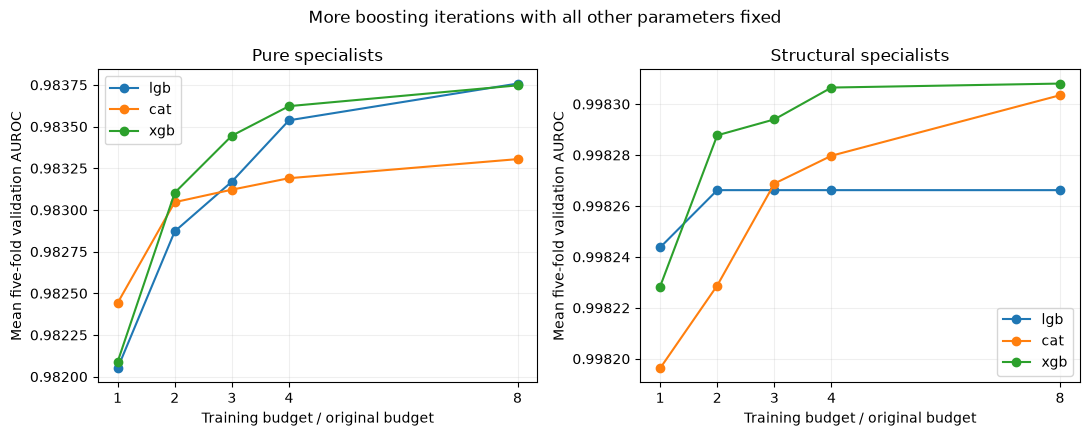

In [7]:
import matplotlib.pyplot as plt

fold_metrics = pd.read_csv(OUT/'fold_iteration_metrics.csv')
curve = fold_metrics.groupby(['branch','multiplier'])[['train_auc','validation_auc']].mean().reset_index()
display(curve)
fig,axes = plt.subplots(1,2,figsize=(11,4.4))
for ax,branch_type in zip(axes,['pure','struct']):
    for family in ['lgb','cat','xgb']:
        part = curve[curve.branch==family+'_'+branch_type]
        ax.plot(part.multiplier,part.validation_auc,marker='o',label=family)
    ax.set_title('Pure specialists' if branch_type=='pure' else 'Structural specialists')
    ax.set_xlabel('Training budget / original budget')
    ax.set_ylabel('Mean five-fold validation AUROC')
    ax.set_xticks(MULTIPLIERS)
    ax.grid(alpha=.2)
    ax.legend()
fig.suptitle('More boosting iterations with all other parameters fixed')
fig.tight_layout()
fig.savefig(OUT/'iteration_curves.png',dpi=180)
plt.show()


## Freeze supported longer-training candidates
Selection uses development AUROC only, keeps the fixed original fusion weights, drops duplicate validation rankings and prefers fewer rounds for tied scores. The holdout cannot change the order.

In [8]:
select_iteration_recipes(freeze=True)

,lgb,cat,xgb,original,canonical,typography,lowercase,wrap60,wrap90,stress_mean,balanced,fold_mean,fold_sd,total_rounds,original_gain,fold_mean_gain,stress_gain,eligible
124,8,8,8,0.998385,0.970190,0.998296,0.997643,0.978782,0.978003,0.975658,0.987022,0.998403,0.000331,28000,0.000114,0.000112,-0.000184,True
99,4,8,8,0.998385,0.970158,0.998295,0.997640,0.978775,0.977990,0.975641,0.987013,0.998404,0.000329,24400,0.000113,0.000112,-0.000201,True
123,8,8,4,0.998383,0.970216,0.998293,0.997632,0.978784,0.978004,0.975668,0.987025,0.998400,0.000332,24400,0.000111,0.000109,-0.000174,True
49,2,8,8,0.998383,0.970109,0.998292,0.997632,0.978782,0.977982,0.975624,0.987004,0.998403,0.000328,22600,0.000111,0.000111,-0.000218,True
98,4,8,4,0.998383,0.970181,0.998292,0.997628,0.978773,0.977985,0.975646,0.987014,0.998399,0.000326,20800,0.000111,0.000108,-0.000196,True
74,3,8,8,0.998383,0.970126,0.998294,0.997635,0.978763,0.977977,0.975622,0.987002,0.998403,0.000327,23500,0.000111,0.000111,-0.000220,True
73,3,8,4,0.998380,0.970153,0.998289,0.997623,0.978763,0.977971,0.975629,0.987005,0.998396,0.000326,19900,0.000108,0.000105,-0.000213,True
122,8,8,3,0.998379,0.970213,0.998289,0.997621,0.978780,0.977996,0.975663,0.987021,0.998398,0.000330,23500,0.000108,0.000106,-0.000179,True
48,2,8,4,0.998378,0.970129,0.998287,0.997620,0.978773,0.977982,0.975628,0.987003,0.998398,0.000329,19000,0.000107,0.000106,-0.000214,True
97,4,8,3,0.998378,0.970181,0.998289,0.997617,0.978767,0.977974,0.975641,0.987009,0.998396,0.000326,19900,0.000106,0.000104,-0.000201,True


Frozen iteration recipes: [{'name': 'longer_01', 'multipliers': {'lgb': 8, 'cat': 8, 'xgb': 8}, 'development': {'original': 0.998385375, 'canonical': 0.9701896249999999, 'typography': 0.998296375, 'lowercase': 0.9976434375000001, 'wrap60': 0.9787820625, 'wrap90': 0.9780030625, 'stress_mean': 0.97565825, 'fold_mean': 0.9984034942622959, 'original_gain': 0.00011387499999993, 'fold_mean_gain': 0.00011189496536345711, 'stress_gain': -0.00018372916666675732}}, {'name': 'longer_02', 'multipliers': {'lgb': 4, 'cat': 8, 'xgb': 8}, 'development': {'original': 0.998384875, 'canonical': 0.9701578125, 'typography': 0.9982954375, 'lowercase': 0.9976403125000001, 'wrap60': 0.9787748125, 'wrap90': 0.9779895625, 'stress_mean': 0.9756407291666666, 'fold_mean': 0.9984038083257747, 'original_gain': 0.00011337499999986012, 'fold_mean_gain': 0.00011220902884223616, 'stress_gain': -0.0002012500000001527}}, {'name': 'longer_03', 'multipliers': {'lgb': 8, 'cat': 8, 'xgb': 4}, 'development': {'original': 0.998

## Frozen assessment and full-data exports

In [9]:
def target_checkpoints(training,target,label):
    staged,static = {},{}
    targets = engine['target_views'](target,KINDS)
    for name in DENSE:
        result = fit_checkpoints(training,targets,name,SEED)
        staged[name] = {m:{kind:values[j*len(target):(j+1)*len(target)] for j,kind in enumerate(KINDS)} for m,values in result['predictions'].items()}
        progress(f'{label}: {name} completed')
    for name in LINEAR:
        values,_ = engine['fit_predict'](training,targets,SPECS[name],SEED)
        static[name] = {kind:values[j*len(target):(j+1)*len(target)] for j,kind in enumerate(KINDS)}
    return staged,static


def fixed_holdout_assessment():
    frozen = json.loads((OUT/'frozen.json').read_text())
    staged,static = target_checkpoints(development,holdout,'Frozen holdout')
    baseline = combine_at(staged,static,{'lgb':1,'cat':1,'xgb':1})
    reference = pd.read_csv(reuse.OLD/'official_holdout_predictions.csv')
    assert reference.id.equals(holdout.id)
    np.testing.assert_allclose(baseline['original'],reference.probability_AI,atol=1e-10,rtol=0)
    y = holdout.label.to_numpy()
    rng = np.random.default_rng(20261108)
    human,ai = np.flatnonzero(y==0),np.flatnonzero(y==1)
    samples = [np.r_[rng.choice(human,len(human)),rng.choice(ai,len(ai))] for _ in range(1000)]
    records = [{'name':'baseline',**scores(y,baseline)}]
    predictions = pd.DataFrame({'id':holdout.id,'label':y})
    for recipe in frozen['recipes']:
        p = combine_at(staged,static,recipe['multipliers'])
        row = {'name':recipe['name'],**scores(y,p)}
        deltas = [roc_auc_score(y[ix],p['original'][ix])-roc_auc_score(y[ix],baseline['original'][ix]) for ix in samples]
        row.update(zip(['original_delta_ci_low','original_delta_median','original_delta_ci_high'],np.quantile(deltas,[.025,.5,.975])))
        records.append(row)
        for kind in KINDS: predictions[recipe['name']+'_'+kind] = p[kind]
    pd.DataFrame(records).to_csv(OUT/'fixed_holdout_metrics.csv',index=False)
    predictions.to_csv(OUT/'fixed_holdout_predictions.csv',index=False)
    display(pd.DataFrame(records))


def full_data_exports():
    frozen = json.loads((OUT/'frozen.json').read_text())
    test = pd.read_csv(data/'test.csv')
    sample = pd.read_csv(data/'sample_submission.csv')
    # Only original test text is needed; no test transformations or fitting.
    staged,static = {},{}
    for name in DENSE:
        result = fit_checkpoints(train,test,name,SEED)
        staged[name] = {m:{'original':values} for m,values in result['predictions'].items()}
        progress(f'Full 10,000-row refit: {name}')
    for name in LINEAR:
        values,_ = engine['fit_predict'](train,test,SPECS[name],SEED)
        static[name] = {'original':values}
    def final_probability(multipliers):
        branches = {name:static[name]['original'] for name in LINEAR}
        branches.update({name:staged[name][multipliers[FAMILY[name]]]['original'] for name in DENSE})
        return engine['historical_fusions'](branches)['B2_v3_corrected']
    baseline = final_probability({'lgb':1,'cat':1,'xgb':1})
    order = pd.DataFrame({'id':test.id,'prediction':baseline}).set_index('id').loc[sample.id,'prediction'].to_numpy()
    saved = pd.read_csv(ROOT/'submission_final_model_improvements.csv')
    validate_submission(saved,sample)
    baseline_delta = float(np.max(np.abs(order-saved.iloc[:,1].to_numpy())))
    assert baseline_delta<=1e-10,baseline_delta
    # Representative independent selected-budget fits cover every boosting library.
    checks = {}
    first = frozen['recipes'][0]['multipliers']
    for name in ['lgb_struct','cat_struct','xgb_struct']:
        family = FAMILY[name]
        count = BASE_ROUNDS[name]*first[family]
        spec = copy.deepcopy(SPECS[name])
        spec['params']['iterations' if family=='cat' else 'n_estimators'] = count
        separate,_ = engine['fit_predict'](train,test,spec,SEED,use_cache=False)
        delta = float(np.max(np.abs(separate-staged[name][first[family]]['original'])))
        assert delta<=1e-10,(name,delta)
        checks[name] = delta
    folder = OUT/'submissions';folder.mkdir(exist_ok=True)
    manifest,rankings = [],[]
    for recipe in frozen['recipes']:
        setting = recipe['multipliers']
        name = recipe['name']+f'_lgb{setting["lgb"]}_cat{setting["cat"]}_xgb{setting["xgb"]}.csv'
        values = final_probability(setting)
        frame = sample[['id']].merge(pd.DataFrame({'id':test.id,sample.columns[1]:values}),on='id',how='left',validate='one_to_one')[sample.columns]
        validate_submission(frame,sample)
        ranking = np.argsort(frame.iloc[:,1],kind='stable')
        assert all(not np.array_equal(ranking,other) for other in rankings),'Duplicate rankings are not distinct candidates.'
        rankings.append(ranking)
        path = folder/name
        frame.to_csv(path,index=False,float_format='%.17g')
        validate_submission(pd.read_csv(path),sample)
        manifest.append({'name':recipe['name'],'file':str(path.relative_to(ROOT)),'rows':len(frame),
                         'sha256':hashlib.sha256(path.read_bytes()).hexdigest(),'multipliers':setting,'development':recipe['development']})
    assert len(list(folder.glob('*.csv')))==len(manifest)
    save_json(OUT/'submission_manifest.json',{'files':manifest,'recipe_sha256':frozen['recipe_sha256'],
              'baseline_reproduction_max_delta':baseline_delta,'independent_selected_budget_max_deltas':checks,
              'baseline_user_reported_public_auc':.98629,'new_public_auc':None,'new_private_auc':None,
              'all_noniteration_parameters_unchanged':True,'test_fitting':False})
    display(pd.DataFrame([{k:v for k,v in row.items() if k!='development'} for row in manifest]))
    print('Verified baseline reproduction:',baseline_delta,'independent selected-budget fits:',checks)


In [10]:
fixed_holdout_assessment()

[0.6 min] Frozen holdout: lgb_pure completed


[0.7 min] Frozen holdout: lgb_struct completed


[1.6 min] Frozen holdout: cat_pure completed


[2.5 min] Frozen holdout: cat_struct completed


[2.7 min] Frozen holdout: xgb_pure completed


[2.8 min] Frozen holdout: xgb_struct completed


,name,original,canonical,typography,lowercase,wrap60,wrap90,stress_mean,balanced,original_delta_ci_low,original_delta_median,original_delta_ci_high
0,baseline,0.999449,0.975318,0.999420,0.999035,0.983251,0.982917,0.980495,0.989972,NaN,NaN,NaN
1,longer_01,0.999486,0.974479,0.999456,0.999104,0.982909,0.982746,0.980045,0.989765,-0.000003,0.000036,0.000090
2,longer_02,0.999484,0.974448,0.999453,0.999110,0.982911,0.982731,0.980030,0.989757,-0.000004,0.000034,0.000084
3,longer_03,0.999484,0.974547,0.999454,0.999099,0.982965,0.982793,0.980102,0.989793,-0.000003,0.000034,0.000087
4,longer_04,0.999489,0.974479,0.999455,0.999104,0.982960,0.982814,0.980084,0.989787,0.000002,0.000038,0.000091
5,longer_05,0.999484,0.974491,0.999452,0.999100,0.982964,0.982780,0.980078,0.989781,-0.000002,0.000034,0.000084


In [11]:
full_data_exports()

[3.0 min] Full 10,000-row refit: lgb_pure


[3.0 min] Full 10,000-row refit: lgb_struct


[4.0 min] Full 10,000-row refit: cat_pure


[5.1 min] Full 10,000-row refit: cat_struct


[5.2 min] Full 10,000-row refit: xgb_pure


[5.3 min] Full 10,000-row refit: xgb_struct


,name,file,rows,sha256,multipliers
0,longer_01,artifacts\longer_training_iterations\submissio...,3000,bf537015329c1c0f968f2cef53c14f93d35897e760e040...,"{'lgb': 8, 'cat': 8, 'xgb': 8}"
1,longer_02,artifacts\longer_training_iterations\submissio...,3000,fd5d48b6a4dfe1d0ccc69c65c6b4766e117c359dbc8f74...,"{'lgb': 4, 'cat': 8, 'xgb': 8}"
2,longer_03,artifacts\longer_training_iterations\submissio...,3000,7903ae2a70e781bf0dd623861ee46324e998036804f418...,"{'lgb': 8, 'cat': 8, 'xgb': 4}"
3,longer_04,artifacts\longer_training_iterations\submissio...,3000,0a392af2b5cfdad86ea45fc76183bdc563cecf41ce6a17...,"{'lgb': 2, 'cat': 8, 'xgb': 8}"
4,longer_05,artifacts\longer_training_iterations\submissio...,3000,cd0968d008066bc5255769b3b7c37ccc0f058fea9d19b0...,"{'lgb': 4, 'cat': 8, 'xgb': 4}"


Verified baseline reproduction: 2.220446049250313e-16 independent selected-budget fits: {'lgb_struct': 0.0, 'cat_struct': 0.0, 'xgb_struct': 0.0}


## Measured outcome

The original nine-specialist recipe and all its noniteration settings were retained. The initial 4× limit gave 0.998371625 pooled development AUROC; the final 8× limit reached **0.998385375**, versus **0.9982715** for the 1× baseline. The best mean-fold AUROC also improved. Pure CatBoost improved over the original model on all five folds. Gains beyond 4× were small, so further increases were not assumed beneficial.

Five candidates were frozen in development-based order before this new holdout comparison. Their ordinary holdout AUROC was **0.999484–0.999489**, versus **0.999449** for the baseline. The first candidate scored **0.999486**; its paired bootstrap interval for the difference included zero. Most intervals included zero, and the historically reused holdout plus multiple comparisons limit confidence. The holdout did not change candidate order.

Formatting stress was slightly worse: the canonical/wrap60/wrap90 mean fell from **0.980495** to **0.980030–0.980102**. This is a small original-text gain with a small robustness cost, not a guaranteed Kaggle improvement. No new Kaggle score is known. The user's reported 0.98629 remains the measured leaderboard reference.

The first candidate uses 3,600 LightGBM trees, 6,800 CatBoost iterations and 3,600 XGBoost rounds for each corresponding pure/structural pair, with the three linear specialists unchanged. Other candidates retain 6,800 CatBoost iterations while varying LightGBM/XGBoost budgets. All learning rates, tree-shape and regularization parameters, preprocessing, language models, seed and ensemble weights are unchanged.

All final boosted branches were fit on the full 10,000 labeled rows. The 1× reconstruction matched `submission_final_model_improvements.csv` within **2.220446049250313e-16** in probability. Independent selected-budget structural fits for LightGBM, CatBoost and XGBoost matched their checkpoint predictions exactly. Each of the five CSVs contains 3,000 unique IDs in template order, the exact `id,label` schema and finite probabilities in [0,1]; all five produce different rankings. Existing submissions were preserved.

Source work is entirely in this notebook. All other new files are experiment artifacts; no persistent Python scripts were created. AI assistance: Codex implemented the controlled study and verified the reported results by executing the notebook. The team should use the measurements, limits and saved configurations when explaining its own modeling decisions.


## Final artifact audit

In [2]:
import subprocess

frozen = json.loads((OUT/'frozen.json').read_text())
manifest = json.loads((OUT/'submission_manifest.json').read_text())
recorded_hash = frozen.pop('recipe_sha256')
assert hashlib.sha256(json.dumps(frozen,sort_keys=True).encode()).hexdigest() == recorded_hash == manifest['recipe_sha256']
assert frozen['active_blend'] == selected_yaml['active_blend'] == engine['base3']['stage1_blend']
assert all(SPECS[name]==selected_yaml['baseline_specs'][name] for name in LINEAR+DENSE)
assert hashlib.sha256((ROOT/'submission_final_model_improvements.csv').read_bytes()).hexdigest() == json.loads((reuse.OLD/'run_summary.json').read_text())['submission_sha256']
sample = pd.read_csv(data/'sample_submission.csv')
assert len(manifest['files'])==5
for row in manifest['files']:
    path = ROOT/row['file']
    assert path.resolve().is_relative_to(ROOT)
    assert hashlib.sha256(path.read_bytes()).hexdigest()==row['sha256']
    validate_submission(pd.read_csv(path),sample)
assert len(list((OUT/'submissions').glob('*.csv')))==5
assert manifest['baseline_reproduction_max_delta']<=1e-10
assert all(delta==0 for delta in manifest['independent_selected_budget_max_deltas'].values())
print('Verified five submission files, hashes, IDs/schema/probabilities, frozen recipes, unchanged original settings and numerical baseline reproduction.')
display(pd.DataFrame([{'candidate':row['name'],'file':row['file'],**row['multipliers'],'development_auc':row['development']['original']} for row in manifest['files']]))
result = subprocess.run(['graphify','update','.'],cwd=ROOT,text=True,capture_output=True)
print(result.stdout)
assert result.returncode==0,result.stderr


Verified five submission files, hashes, IDs/schema/probabilities, frozen recipes, unchanged original settings and numerical baseline reproduction.


,candidate,file,lgb,cat,xgb,development_auc
0,longer_01,artifacts\longer_training_iterations\submissio...,8,8,8,0.998385
1,longer_02,artifacts\longer_training_iterations\submissio...,4,8,8,0.998385
2,longer_03,artifacts\longer_training_iterations\submissio...,8,8,4,0.998383
3,longer_04,artifacts\longer_training_iterations\submissio...,2,8,8,0.998383
4,longer_05,artifacts\longer_training_iterations\submissio...,4,8,4,0.998383


Re-extracting code files in . (no LLM needed)...
[graphify watch] No code-graph topology changes detected; outputs left untouched.
Code graph updated. For doc/paper/image changes run /graphify --update in your AI assistant.

